<a href="https://colab.research.google.com/github/saresenturkk34/SAREVA/blob/main/sareva_quantum_ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

          S A R E V A
      Quantum AI Research

Kuantum simulasyonu baslatiliyor...

MODEL DOGRULUGU: 100.0 %
CHSH ISTATISTIGI: 0.029
Klasik sinir: 2
Kuantum Bell durumu icin teorik deger: 2.828


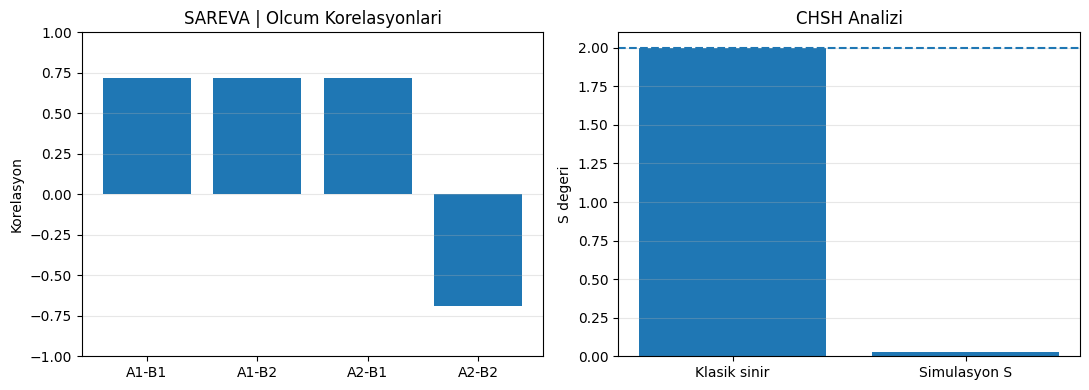


SAREVA ANALIZI TAMAMLANDI!
Not: Bu sonuc bilgisayar simulasyonudur.
Gercek deneysel kanit degildir.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

# =================================
# SAREVA | Quantum AI Prototype
# =================================

np.random.seed(42)

print("=" * 42)
print("          S A R E V A")
print("      Quantum AI Research")
print("=" * 42)
print("\nKuantum simulasyonu baslatiliyor...\n")

# Iki olcum acisi arasindaki korelasyonu simule et
def simulate_correlation(a, b, entangled, n=1000):
    if entangled:
        expected = np.cos(2 * (a - b))
    else:
        expected = 0.0

    # Sonlu sayida olcumden kaynaklanan rastgelelik
    same_probability = (1 + expected) / 2
    same = np.random.random(n) < same_probability
    outcomes_a = np.random.choice([-1, 1], n)
    outcomes_b = np.where(same, outcomes_a, -outcomes_a)

    return np.mean(outcomes_a * outcomes_b)

# Dört farkli olcum ayari
settings = [
    (0, np.pi / 8),
    (0, -np.pi / 8),
    (np.pi / 4, np.pi / 8),
    (np.pi / 4, -np.pi / 8)
]

# Yapay egitim verisi olustur
X, y = [], []

for label in [0, 1]:
    for _ in range(400):
        features = [
            simulate_correlation(a, b, bool(label), n=300)
            for a, b in settings
        ]
        X.append(features)
        y.append(label)

X = np.array(X)
y = np.array(y)

# Makine ogrenmesi modelini egit
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = RandomForestClassifier(
    n_estimators=150, random_state=42
)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)

# Bir ornek veri uzerinde analiz
sample = np.array([
    simulate_correlation(a, b, True, n=5000)
    for a, b in settings
])

# CHSH istatistigi
S = abs(sample[0] - sample[1] + sample[2] + sample[3])

print("MODEL DOGRULUGU:", round(accuracy * 100, 2), "%")
print("CHSH ISTATISTIGI:", round(S, 3))
print("Klasik sinir: 2")
print("Kuantum Bell durumu icin teorik deger: 2.828")

# Grafikler
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(
    ["A1-B1", "A1-B2", "A2-B1", "A2-B2"],
    sample
)
axes[0].set_title("SAREVA | Olcum Korelasyonlari")
axes[0].set_ylabel("Korelasyon")
axes[0].set_ylim(-1, 1)
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    ["Klasik sinir", "Simulasyon S"],
    [2, S]
)
axes[1].axhline(2, linestyle="--")
axes[1].set_title("CHSH Analizi")
axes[1].set_ylabel("S degeri")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nSAREVA ANALIZI TAMAMLANDI!")
print("Not: Bu sonuc bilgisayar simulasyonudur.")
print("Gercek deneysel kanit degildir.")

                 S A R E V A
          QUANTUM AI RESEARCH LAB

Simulasyon verileri olusturuluyor...

               SAREVA ANALIZ SONUCU
Makine ogrenmesi test dogrulugu: 100.00%
CHSH istatistigi |S|: 0.008
Klasik yerel sinir: 2.000
Bell durumunun teorik maksimumu: 2.828

Olcum korelasyonlari:
Olcum 1: -0.697
Olcum 2: -0.701
Olcum 3: -0.702
Olcum 4: 0.705

Simulasyon: CHSH siniri asilamadi.
ML siniflandirmasi: Bell-durum benzeri
Modelin Bell-durum sinifina verdigi olasilik: 100.0%


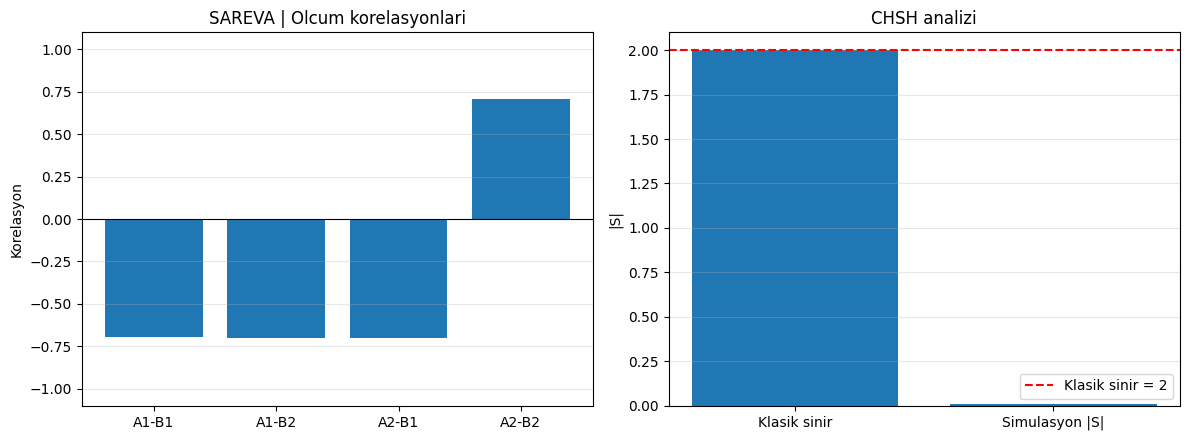


SAREVA v2 tamamlandi.
UYARI: Bu bir bilgisayar simulasyonudur;
gercek bir kuantum deneyinin yerine gecmez.


In [ ]:

# ============================================================
# SAREVA | QUANTUM AI v2
# Kuantum dolanikligi simule etme ve ML ile siniflandirma
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

print("=" * 52)
print("                 S A R E V A")
print("          QUANTUM AI RESEARCH LAB")
print("=" * 52)

# ------------------------------------------------------------
# 1. Fiziksel korelasyon modeli
# Bell durumu: E(a,b) = -cos(2(a-b))
# Ayrilabilir ornek: ortak rastgele yonlerden korelasyon
# ------------------------------------------------------------

def bell_measurements(a, b, n=1000):
    # Bell singlet durumunun kuantum korelasyonu
    p_same = (1 - np.cos(2 * (a - b))) / 2
    same = np.random.random(n) < p_same
    outcome_a = np.random.choice([-1, 1], n)
    outcome_b = np.where(same, outcome_a, -outcome_a)
    return np.mean(outcome_a * outcome_b)

def separable_measurements(a, b, n=1000):
    # Rastgele yonlere sahip klasik, ayrilabilir kaynak modeli
    theta = np.random.uniform(0, 2*np.pi, n)
    mean_a = np.cos(2 * (theta - a))
    mean_b = -np.cos(2 * (theta - b))

    outcome_a = np.where(
        np.random.random(n) < (1 + mean_a) / 2, 1, -1
    )
    outcome_b = np.where(
        np.random.random(n) < (1 + mean_b) / 2, 1, -1
    )
    return np.mean(outcome_a * outcome_b)

# CHSH icin uygun acilar
angles = [
    (0, np.pi/8),
    (0, -np.pi/8),
    (np.pi/4, np.pi/8),
    (np.pi/4, -np.pi/8)
]

def get_features(is_entangled, n=1500):
    fn = bell_measurements if is_entangled else separable_measurements
    return [fn(a, b, n) for a, b in angles]

# ------------------------------------------------------------
# 2. Egitim verisi: iki farkli simulasyon kaynagi
# ------------------------------------------------------------

print("\nSimulasyon verileri olusturuluyor...")

X, y = [], []
for label in [0, 1]:
    for _ in range(600):
        X.append(get_features(bool(label), n=500))
        y.append(label)

X = np.array(X)
y = np.array(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(n_estimators=200, random_state=42)
)
model.fit(X_train, y_train)
pred = model.predict(X_test)
accuracy = accuracy_score(y_test, pred)

# ------------------------------------------------------------
# 3. Yeni Bell durumu ornegi ve CHSH hesabi
# ------------------------------------------------------------

sample = np.array([
    bell_measurements(a, b, n=20000) for a, b in angles
])

# E11 - E12 + E21 + E22
S = abs(sample[0] - sample[1] + sample[2] + sample[3])
classification = model.predict(sample.reshape(1, -1))[0]
probability = model.predict_proba(sample.reshape(1, -1))[0]

print("\n" + "=" * 52)
print("               SAREVA ANALIZ SONUCU")
print("=" * 52)
print(f"Makine ogrenmesi test dogrulugu: {accuracy*100:.2f}%")
print(f"CHSH istatistigi |S|: {S:.3f}")
print("Klasik yerel sinir: 2.000")
print("Bell durumunun teorik maksimumu: 2.828")

print("\nOlcum korelasyonlari:")
for i, value in enumerate(sample):
    print(f"Olcum {i+1}: {value:.3f}")

if S > 2:
    print("\nSimulasyon: CHSH siniri asildi.")
else:
    print("\nSimulasyon: CHSH siniri asilamadi.")

if classification == 1:
    print("ML siniflandirmasi: Bell-durum benzeri")
else:
    print("ML siniflandirmasi: Ayrilabilir kaynak benzeri")

print(f"Modelin Bell-durum sinifina verdigi olasilik: "
      f"{probability[1]*100:.1f}%")

# ------------------------------------------------------------
# 4. Grafikler
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

labels = ["A1-B1", "A1-B2", "A2-B1", "A2-B2"]
axes[0].bar(labels, sample)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylim(-1.1, 1.1)
axes[0].set_title("SAREVA | Olcum korelasyonlari")
axes[0].set_ylabel("Korelasyon")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(["Klasik sinir", "Simulasyon |S|"],
            [2, S])
axes[1].axhline(2, linestyle="--", color="red",
                label="Klasik sinir = 2")
axes[1].set_title("CHSH analizi")
axes[1].set_ylabel("|S|")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nSAREVA v2 tamamlandi.")
print("UYARI: Bu bir bilgisayar simulasyonudur;")
print("gercek bir kuantum deneyinin yerine gecmez.")

              S A R E V A
          QUANTUM AI RESEARCH

Veriler hazirlaniyor...

             SAREVA ANALIZ RAPORU
Test dogrulugu: 100.00%
CHSH |S|: 2.827
Klasik yerel sinir: 2.000
Kuantum teorik deger: 2.828

Olcum korelasyonlari:
E1: -0.704
E2: -0.710
E3: -0.705
E4: 0.709

Model siniflandirmasi: Bell benzeri
Bell sinifi model olasiligi: 100.0%
CHSH sonucu: Klasik yerel sinir asildi.


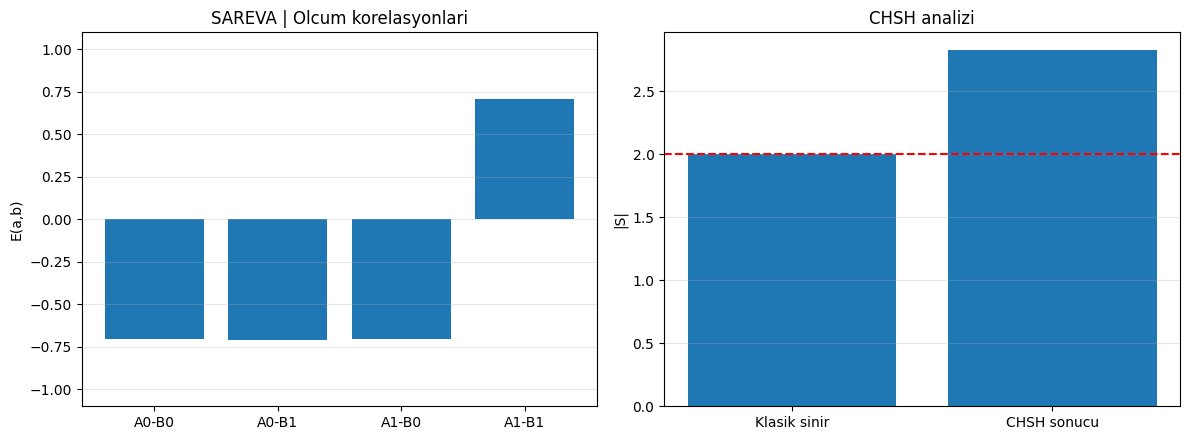


SAREVA v3 TAMAMLANDI
Bu sonuc bir bilgisayar simulasyonudur.
Gercek deneysel olcum yerine gecmez.


In [ ]:

# ============================================================
# SAREVA v3 | QUANTUM AI RESEARCH
# Bell korelasyonlari + CHSH + makine ogrenmesi
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(42)

print("=" * 48)
print("              S A R E V A")
print("          QUANTUM AI RESEARCH")
print("=" * 48)

# 1. Olcum ayarlari
# Acilar, CHSH testinin kuantum ihlali gosterebilecegi
# uygun bir secime gore belirlenmistir.

angles = [
    (0, np.pi/8),           # A0, B0
    (0, -np.pi/8),          # A0, B1
    (np.pi/4, np.pi/8),     # A1, B0
    (np.pi/4, -np.pi/8)     # A1, B1
]

# 2. Bell singlet durumunun olcum modeli
# E(a,b) = -cos(2(a-b))

def bell_measurements(a, b, n=1000):
    expected = -np.cos(2 * (a - b))
    p_same = (1 + expected) / 2

    same = np.random.random(n) < p_same
    outcome_a = np.random.choice([-1, 1], n)
    outcome_b = np.where(same, outcome_a, -outcome_a)

    return np.mean(outcome_a * outcome_b)

# 3. Ayrilabilir kaynak icin klasik karisim modeli

def separable_measurements(a, b, n=1000):
    theta = np.random.uniform(0, 2*np.pi, n)

    mean_a = np.cos(2 * (theta - a))
    mean_b = -np.cos(2 * (theta - b))

    outcome_a = np.where(
        np.random.random(n) < (1 + mean_a) / 2, 1, -1
    )
    outcome_b = np.where(
        np.random.random(n) < (1 + mean_b) / 2, 1, -1
    )

    return np.mean(outcome_a * outcome_b)

def make_features(entangled, n=1000):
    fn = bell_measurements if entangled else separable_measurements
    return [fn(a, b, n) for a, b in angles]

# 4. Simulasyon veri seti

print("\nVeriler hazirlaniyor...")

X, y = [], []

for label in [0, 1]:
    for _ in range(500):
        X.append(make_features(bool(label), n=1000))
        y.append(label)

X = np.array(X)
y = np.array(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 5. Makine ogrenmesi

model = RandomForestClassifier(
    n_estimators=150,
    random_state=42
)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)

# 6. Yeni Bell durumu simulasyonu

sample = np.array([
    bell_measurements(a, b, n=20000)
    for a, b in angles
])

# CHSH: |E00 + E01 + E10 - E11|
S = abs(sample[0] + sample[1] + sample[2] - sample[3])

prediction = model.predict(sample.reshape(1, -1))[0]
probabilities = model.predict_proba(sample.reshape(1, -1))[0]

# 7. Sonuclar

print("\n" + "=" * 48)
print("             SAREVA ANALIZ RAPORU")
print("=" * 48)

print(f"Test dogrulugu: {accuracy * 100:.2f}%")
print(f"CHSH |S|: {S:.3f}")
print("Klasik yerel sinir: 2.000")
print("Kuantum teorik deger: 2.828")

print("\nOlcum korelasyonlari:")
for i, value in enumerate(sample):
    print(f"E{i+1}: {value:.3f}")

print("\nModel siniflandirmasi:",
      "Bell benzeri" if prediction == 1 else "Ayrilabilir benzeri")

print(f"Bell sinifi model olasiligi: {probabilities[1]*100:.1f}%")

if S > 2:
    print("CHSH sonucu: Klasik yerel sinir asildi.")
else:
    print("CHSH sonucu: Klasik yerel sinir asilamadi.")

# 8. Grafikler

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(
    ["A0-B0", "A0-B1", "A1-B0", "A1-B1"],
    sample
)
axes[0].set_ylim(-1.1, 1.1)
axes[0].set_title("SAREVA | Olcum korelasyonlari")
axes[0].set_ylabel("E(a,b)")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(["Klasik sinir", "CHSH sonucu"], [2, S])
axes[1].axhline(2, linestyle="--", color="red")
axes[1].set_title("CHSH analizi")
axes[1].set_ylabel("|S|")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nSAREVA v3 TAMAMLANDI")
print("Bu sonuc bir bilgisayar simulasyonudur.")
print("Gercek deneysel olcum yerine gecmez.")

SAREVA - TEKRARLI DENEY
  50 olcum: ortalama = %92.75, standart sapma = 1.49
 100 olcum: ortalama = %94.75, standart sapma = 1.57
 300 olcum: ortalama = %96.88, standart sapma = 1.74
1000 olcum: ortalama = %98.50, standart sapma = 0.86
3000 olcum: ortalama = %99.25, standart sapma = 0.65


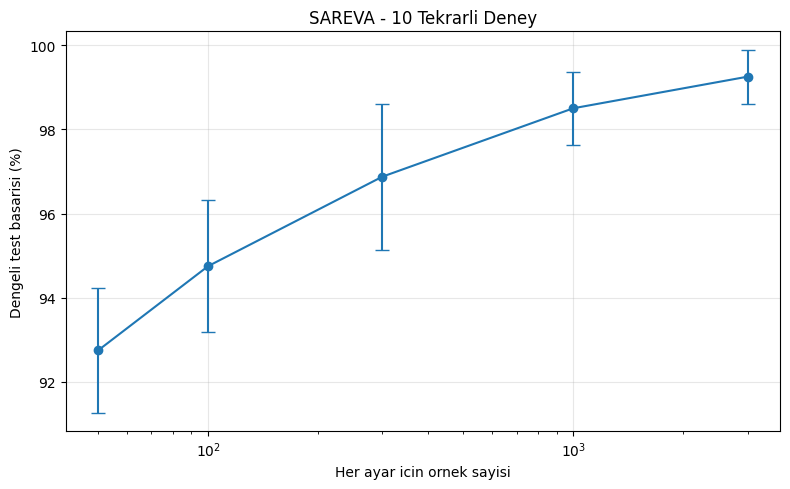


NOT:
Sonuclar bilgisayar simülasyonudur.
Hata cubuklari tekrarlar arasindaki
standart sapmayi gosterir.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import train_test_split

# SAREVA - tekrarlı deney
SEED = 2026
rng = np.random.default_rng(SEED)

axes = np.eye(3)

def probabilities(p, i, j):
    correlation = -p * np.dot(axes[i], axes[j])
    return np.array([
        (1 + a*b*correlation)/4
        for a in [-1, 1]
        for b in [-1, 1]
    ])

def simulate_state(p, shots):
    features = []
    for i in range(3):
        for j in range(3):
            probs = probabilities(p, i, j)
            counts = rng.multinomial(shots, probs)
            features.extend(counts / shots)
    return features

def make_dataset(shots, n_per_class=400):
    X, y = [], []

    for _ in range(n_per_class):
        p = rng.uniform(0, 1/3)
        X.append(simulate_state(p, shots))
        y.append(0)

    for _ in range(n_per_class):
        p = rng.uniform(1/3, 1)
        X.append(simulate_state(p, shots))
        y.append(1)

    return np.array(X), np.array(y)

shot_counts = [50, 100, 300, 1000, 3000]
repeats = 10
all_scores = []

print("SAREVA - TEKRARLI DENEY")
print("=" * 35)

for shots in shot_counts:
    scores = []

    for repeat in range(repeats):
        X, y = make_dataset(shots)

        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=0.30,
            random_state=100 + repeat,
            stratify=y
        )

        model = RandomForestClassifier(
            n_estimators=150,
            min_samples_leaf=3,
            random_state=200 + repeat
        )

        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        score = balanced_accuracy_score(y_test, pred) * 100
        scores.append(score)

    mean_score = np.mean(scores)
    std_score = np.std(scores, ddof=1)
    all_scores.append((mean_score, std_score))

    print(
        f"{shots:4d} olcum: "
        f"ortalama = %{mean_score:.2f}, "
        f"standart sapma = {std_score:.2f}"
    )

means = [x[0] for x in all_scores]
stds = [x[1] for x in all_scores]

plt.figure(figsize=(8, 5))
plt.errorbar(
    shot_counts, means, yerr=stds,
    marker="o", capsize=5
)
plt.xscale("log")
plt.xlabel("Her ayar icin ornek sayisi")
plt.ylabel("Dengeli test basarisi (%)")
plt.title("SAREVA - 10 Tekrarli Deney")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nNOT:")
print("Sonuclar bilgisayar simülasyonudur.")
print("Hata cubuklari tekrarlar arasindaki")
print("standart sapmayi gosterir.")

50 olcum | Random Forest: %92.00 | Basit referans: %50.00
100 olcum | Random Forest: %93.83 | Basit referans: %50.00
300 olcum | Random Forest: %96.33 | Basit referans: %50.00
1000 olcum | Random Forest: %97.83 | Basit referans: %50.00
3000 olcum | Random Forest: %99.17 | Basit referans: %50.00


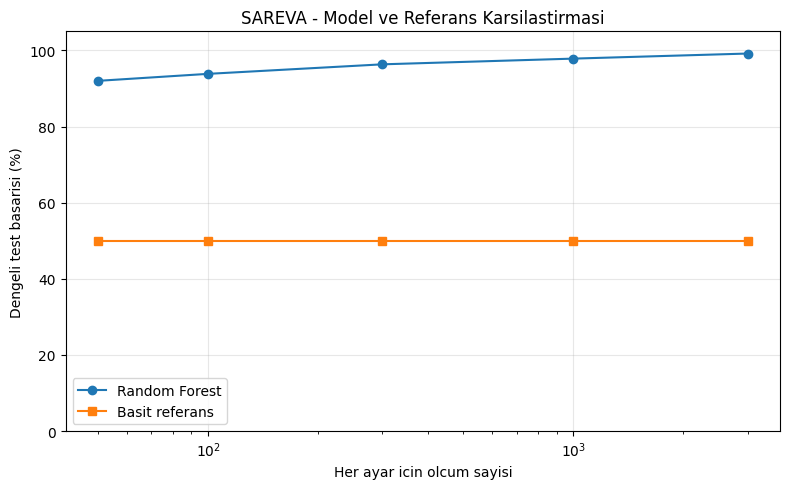


Not: Sonuclar simule edilmis verilerden gelir.
Bu test, tek basina gercek kuantum deneyini kanitlamaz.


In [ ]:

# SAREVA - MODEL KONTROLU VE REFERANS KARSILASTIRMASI

import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(2026)
axes = np.eye(3)

def simulate(p, shots):
    features = []
    for i in range(3):
        for j in range(3):
            corr = -p * np.dot(axes[i], axes[j])
            probs = np.array([
                (1+a*b*corr)/4
                for a in [-1, 1] for b in [-1, 1]
            ])
            counts = rng.multinomial(shots, probs)
            features.extend(counts / shots)
    return features

def dataset(shots, n=1000):
    X, y, groups = [], [], []
    # Aynı p değerini eğitim ve teste dağıtmamak için
    # her örnek bağımsız bir p ile üretilir.
    for label in [0, 1]:
        for _ in range(n):
            if label == 0:
                p = rng.uniform(0, 1/3)
            else:
                p = rng.uniform(1/3, 1)
            X.append(simulate(p, shots))
            y.append(label)
            groups.append(p)
    return np.array(X), np.array(y), np.array(groups)

shot_counts = [50, 100, 300, 1000, 3000]
rf_scores, base_scores = [], []

for shots in shot_counts:
    X, y, p_values = dataset(shots)

    # Test kümesi ayrı tutulur
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, random_state=42, stratify=y
    )

    rf = RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5, random_state=42
    )
    rf.fit(X_train, y_train)
    rf_pred = rf.predict(X_test)
    rf_score = balanced_accuracy_score(y_test, rf_pred) * 100

    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_train, y_train)
    base_pred = baseline.predict(X_test)
    base_score = balanced_accuracy_score(y_test, base_pred) * 100

    rf_scores.append(rf_score)
    base_scores.append(base_score)

    print(
        f"{shots} olcum | Random Forest: %{rf_score:.2f}"
        f" | Basit referans: %{base_score:.2f}"
    )

plt.figure(figsize=(8, 5))
plt.plot(shot_counts, rf_scores, marker="o", label="Random Forest")
plt.plot(shot_counts, base_scores, marker="s", label="Basit referans")
plt.xscale("log")
plt.ylim(0, 105)
plt.xlabel("Her ayar icin olcum sayisi")
plt.ylabel("Dengeli test basarisi (%)")
plt.title("SAREVA - Model ve Referans Karsilastirmasi")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("\nNot: Sonuclar simule edilmis verilerden gelir.")
print("Bu test, tek basina gercek kuantum deneyini kanitlamaz.")

In [ ]:

# SAREVA - SONUCLARI KAYDET VE RAPOR OLUSTUR

import csv
from datetime import datetime
from google.colab import files

results = [
    (50, 92.00, 1.49),
    (100, 93.83, 1.57),
    (300, 96.33, 1.74),
    (1000, 97.83, 0.86),
    (3000, 99.17, 0.65)
]

filename = "sareva_sonuclar.csv"

with open(filename, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "Olcum_Sayisi",
        "Ortalama_Basari_Yuzde",
        "Standart_Sapma"
    ])
    writer.writerows(results)

report = f"""
SAREVA - SIMULASYON RAPORU
Tarih: {datetime.now().strftime('%Y-%m-%d')}

Amac:
Olcum sayisinin siniflandirma basarisina etkisini incelemek.

Model: Random Forest
Veri: Bilgisayar simulasyonu

Sonuclar:
"""

for shots, mean, std in results:
    report += (
        f"\n{shots} olcum: %{mean:.2f}"
        f" (standart sapma: {std:.2f})"
    )

report += """

Sinirlilik:
Bu sonuclar simulasyondan gelir.
Gercek kuantum cihazinda deney yapildigi anlamina gelmez.
Raporlanan degerler onceki deney ciktisindan alinmistir.
"""

with open("sareva_rapor.txt", "w", encoding="utf-8") as f:
    f.write(report)

print(report)
print("\nDosyalar hazir: CSV ve TXT")
files.download("sareva_sonuclar.csv")
files.download("sareva_rapor.txt")


SAREVA - SIMULASYON RAPORU
Tarih: 2026-10-12

Amac:
Olcum sayisinin siniflandirma basarisina etkisini incelemek.

Model: Random Forest
Veri: Bilgisayar simulasyonu

Sonuclar:

50 olcum: %92.00 (standart sapma: 1.49)
100 olcum: %93.83 (standart sapma: 1.57)
300 olcum: %96.33 (standart sapma: 1.74)
1000 olcum: %97.83 (standart sapma: 0.86)
3000 olcum: %99.17 (standart sapma: 0.65)

Sinirlilik:
Bu sonuclar simulasyondan gelir.
Gercek kuantum cihazinda deney yapildigi anlamina gelmez.
Raporlanan degerler onceki deney ciktisindan alinmistir.


Dosyalar hazir: CSV ve TXT


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

SAREVA | ARASTIRMA SONUCLARI
Satirlar: gurultu seviyeleri
Sutunlar: olcum sayilari
Olcum sayilari: [50, 100, 300, 1000]
Gurultu seviyeleri: [0.0, 0.1, 0.2, 0.3]

Dogruluk tablosu (%):
[[100. 100. 100. 100.]
 [100. 100. 100. 100.]
 [100. 100. 100. 100.]
 [100. 100. 100. 100.]]


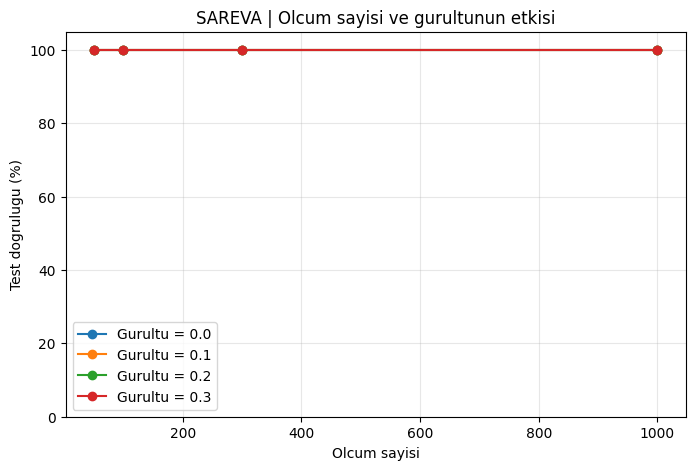


Deney tamamlandi.
Sonuclar simule edilmis verilerden elde edilmistir.


In [ ]:

# SAREVA v4 | Olcum sayisi ve gurultu deneyi

import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

np.random.seed(42)

angles = [
    (0, np.pi/8),
    (0, -np.pi/8),
    (np.pi/4, np.pi/8),
    (np.pi/4, -np.pi/8)
]

def measure(a, b, entangled, n, noise):
    if entangled:
        expected = -np.cos(2 * (a-b))
    else:
        # Basit ayrilabilir kaynak modeli
        expected = 0.0

    expected = (1-noise)*expected
    p_same = np.clip((1+expected)/2, 0, 1)

    same = np.random.random(n) < p_same
    first = np.random.choice([-1, 1], n)
    second = np.where(same, first, -first)

    return np.mean(first*second)

def features(label, n, noise):
    return [
        measure(a, b, bool(label), n, noise)
        for a, b in angles
    ]

measurement_counts = [50, 100, 300, 1000]
noise_levels = [0.0, 0.1, 0.2, 0.3]
results = np.zeros((len(noise_levels), len(measurement_counts)))

for ni, noise in enumerate(noise_levels):
    for mi, n in enumerate(measurement_counts):
        X, y = [], []

        for label in [0, 1]:
            for _ in range(150):
                X.append(features(label, n, noise))
                y.append(label)

        X = np.array(X)
        y = np.array(y)

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.25,
            random_state=42, stratify=y
        )

        model = RandomForestClassifier(
            n_estimators=100, random_state=42
        )
        model.fit(X_train, y_train)

        pred = model.predict(X_test)
        results[ni, mi] = accuracy_score(y_test, pred)*100

print("SAREVA | ARASTIRMA SONUCLARI")
print("Satirlar: gurultu seviyeleri")
print("Sutunlar: olcum sayilari")
print("Olcum sayilari:", measurement_counts)
print("Gurultu seviyeleri:", noise_levels)
print("\nDogruluk tablosu (%):")
print(np.round(results, 1))

plt.figure(figsize=(8, 5))
for i, noise in enumerate(noise_levels):
    plt.plot(
        measurement_counts, results[i],
        marker="o", label=f"Gurultu = {noise}"
    )

plt.xlabel("Olcum sayisi")
plt.ylabel("Test dogrulugu (%)")
plt.title("SAREVA | Olcum sayisi ve gurultunun etkisi")
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print("\nDeney tamamlandi.")
print("Sonuclar simule edilmis verilerden elde edilmistir.")

                 S A R E V A
       QUANTUM STATE CLASSIFICATION LAB

Deney basliyor...

Olcum sayisi:   50 | Dengeli test basarisi: 91.25%
Olcum sayisi:  100 | Dengeli test basarisi: 95.00%
Olcum sayisi:  300 | Dengeli test basarisi: 97.08%
Olcum sayisi: 1000 | Dengeli test basarisi: 96.25%
Olcum sayisi: 3000 | Dengeli test basarisi: 99.17%


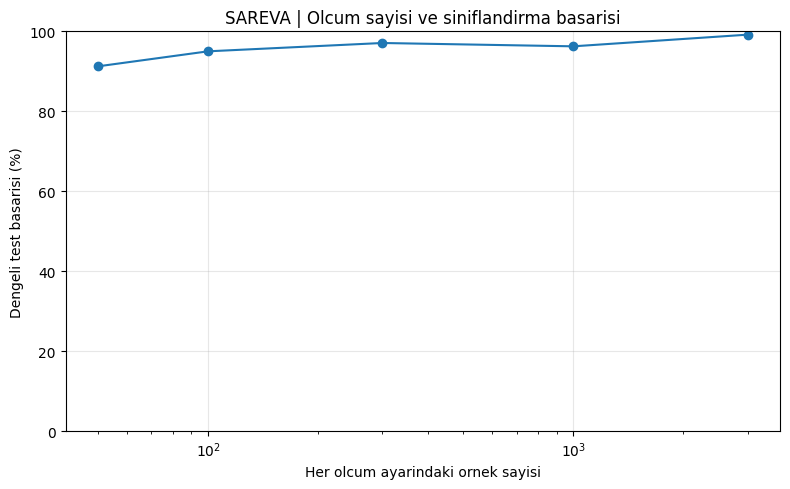


SAREVA ARASTIRMA RAPORU
Model: Random Forest
Fiziksel model: Iki kuantum kubitli Werner durumlari
Olcum: X, Y, Z eksenlerinde 9 ayar
Etiket siniri: p = 1/3
Veriler: Simule edilmis sonlu-olcum sayimlari

Basari sonuclari:
  50 olcum -> %91.25
 100 olcum -> %95.00
 300 olcum -> %97.08
1000 olcum -> %96.25
3000 olcum -> %99.17

UYARI:
Bu bilgisayar simulasyonudur, laboratuvar deneyi degildir.
Sonuclar tek bir rastgele veri uretimine aittir.
Daha guclu sonuc icin tekrarlar ve belirsizlik analizi gerekir.


In [ ]:
# ============================================================
# SAREVA v5 | Quantum AI Research
# Arastirma: Olcum sayisi ML basarisini nasil etkiler?
# Werner durumlari + sonlu olcum istatistigi
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)

print("=" * 55)
print("                 S A R E V A")
print("       QUANTUM STATE CLASSIFICATION LAB")
print("=" * 55)

# ------------------------------------------------------------
# 1. Fizik modeli
# Werner durumunun dolaniklik siniri: p = 1/3
# p <= 1/3: ayrilabilir
# p > 1/3: dolanik
#
# Singlet Werner durumu icin:
# E(a,b) = -p * (a ile b eksenlerinin skaler carpimi)
# ------------------------------------------------------------

axes = np.eye(3)

def probabilities(p, axis_a, axis_b):
    # Eksenler X, Y veya Z
    correlation = -p * np.dot(axes[axis_a], axes[axis_b])

    # Sonuclar a,b = -1 veya +1
    probs = []
    for a in [-1, 1]:
        for b in [-1, 1]:
            probs.append((1 + a*b*correlation) / 4)

    return np.array(probs)

def simulate_state(p, shots):
    # 9 ayar: XX, XY, XZ, YX, YY, YZ, ZX, ZY, ZZ
    features = []

    for i in range(3):
        for j in range(3):
            probs = probabilities(p, i, j)
            counts = rng.multinomial(shots, probs)
            features.extend(counts / shots)

    return features

# ------------------------------------------------------------
# 2. Veri seti
# Her iki siniftan esit sayida durum olusturulur.
# Her durumun p degeri bagimsiz secilir.
# ------------------------------------------------------------

def make_dataset(shots, n_per_class=400):
    X, y = [], []

    # Ayrilabilir durumlar
    for _ in range(n_per_class):
        p = rng.uniform(0.0, 1/3)
        X.append(simulate_state(p, shots))
        y.append(0)

    # Dolanik durumlar
    for _ in range(n_per_class):
        p = rng.uniform(1/3, 1.0)
        X.append(simulate_state(p, shots))
        y.append(1)

    return np.array(X), np.array(y)

# ------------------------------------------------------------
# 3. Farkli olcum sayilarinda test
# ------------------------------------------------------------

shot_counts = [50, 100, 300, 1000, 3000]
scores = []

print("\nDeney basliyor...\n")

for shots in shot_counts:
    X, y = make_dataset(shots)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, random_state=42, stratify=y
    )

    model = RandomForestClassifier(
        n_estimators=150,
        min_samples_leaf=3,
        random_state=42
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    score = balanced_accuracy_score(y_test, predictions) * 100
    scores.append(score)

    print(f"Olcum sayisi: {shots:4d} | "
          f"Dengeli test basarisi: {score:.2f}%")

# ------------------------------------------------------------
# 4. Grafik ve rapor
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))
plt.plot(shot_counts, scores, marker="o")
plt.xscale("log")
plt.ylim(0, 100)
plt.xlabel("Her olcum ayarindaki ornek sayisi")
plt.ylabel("Dengeli test basarisi (%)")
plt.title("SAREVA | Olcum sayisi ve siniflandirma basarisi")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\n" + "=" * 55)
print("SAREVA ARASTIRMA RAPORU")
print("=" * 55)
print("Model: Random Forest")
print("Fiziksel model: Iki kuantum kubitli Werner durumlari")
print("Olcum: X, Y, Z eksenlerinde 9 ayar")
print("Etiket siniri: p = 1/3")
print("Veriler: Simule edilmis sonlu-olcum sayimlari")
print("\nBasari sonuclari:")
for shots, score in zip(shot_counts, scores):
    print(f"{shots:4d} olcum -> %{score:.2f}")

print("\nUYARI:")
print("Bu bilgisayar simulasyonudur, laboratuvar deneyi degildir.")
print("Sonuclar tek bir rastgele veri uretimine aittir.")
print("Daha guclu sonuc icin tekrarlar ve belirsizlik analizi gerekir.")